In [1]:
import scanpy as sc
adata_HD = sc.read("./h5ad/adata_HD.h5ad")

In [2]:
import numpy as np
from scipy.spatial.transform import Rotation

def estimate_similarity_transform(src_points, dst_points):
    """
    Estimate 2D similarity transform parameters s, R, t from src_points to dst_points.
    q = s * R * p + t

    Parameters:
        src_points: numpy array, shape (N, 2), source point set
        dst_points: numpy array, shape (N, 2), target point set
    Returns:
        s: float, scaling factor
        R: numpy array, shape (2, 2), rotation matrix
        t: numpy array, shape (2,), translation vector
    """
    # 0. Input validation
    src = np.asarray(src_points, dtype=np.float64)
    dst = np.asarray(dst_points, dtype=np.float64)
    if src.shape != dst.shape or src.shape[1] != 2:
        raise ValueError("Input point sets must have the same shape (N, 2)")

    N = src.shape[0]
    if N < 2:
        raise ValueError("At least 2 point pairs are required to estimate a similarity transform")

    # 1. Compute centroids
    mean_src = np.mean(src, axis=0)
    mean_dst = np.mean(dst, axis=0)

    # 2. Center the point sets
    src_centered = src - mean_src
    dst_centered = dst - mean_dst

    # 3. Compute variance of the source point set (denominator)
    var_src = np.sum(src_centered ** 2)
    if var_src < 1e-12:
        raise ValueError("Source point set is degenerate (all points coincide), cannot estimate transform")

    # 4. Compute cross-covariance matrix H (2x2)
    H = src_centered.T @ dst_centered

    # 5. SVD decomposition
    U, S, Vt = np.linalg.svd(H)

    # 6. Compute rotation matrix R
    R = Vt.T @ U.T

    # Prevent reflection (ensure det(R) = 1)
    if np.linalg.det(R) < 0:
        Vt[-1, :] *= -1
        R = Vt.T @ U.T

    # 7. Compute scaling factor s
    s = np.sum(S) / var_src

    # 8. Compute translation vector t
    t = mean_dst - s * (R @ mean_src)

    return s, R, t

In [3]:
'''
batch = "nS02"
src= [[5937.066794664968,2956.6010715420302],
[6676.903409029924,6122.46891006973],
[1837.9392139134206,11903.39257387802],
[12531.315511526154,12794.507265345748],
[15169.01499827063,12830.151853004458],
[8360.898755457189,7483.4637041980895],
[8111.386641846224,1031.7933379717379],
[12709.5384498197,1673.395915828502]]


# point_index, x, y
dst = [[382.16369393699074,241.0614880076527],
[445.429677264731,407.49378885166493],
[179.96253465973274,831.2826054222103],
[943.7577830332932,830.244765438643],
[1048.9587045607452,803.3329017920854],
[606.1362209219351,509.74893473873067],
[518.7144677037186,69.68768815776843],
[836.2265420431065,140.54875195883358]]
'''

'''
batch = "nS06"
src = [[11620.41506498,  8006.57763281],
        [12626.35210902, 12962.89260837],
        [11384.38597218,  2624.4600496 ],
        [ 2167.25953375,  9013.60970385],
        [10309.42701214,  2381.71633953],
        [ 3111.56660442,  7225.0963004 ],
        [ 9257.3354129 ,  5383.11185076]]
dst = [[826.81487479, 605.01053253],
        [910.47476365, 931.56626615],
        [792.21286343, 242.31893431],
        [186.11550762, 712.87315734],
        [720.56856668, 253.58332066],
        [239.83956373, 578.37107574],
        [651.67624007, 443.27981253]]
'''

'''
batch = "nS01"
src= [[3965.941976959115, 7178.830247103894],
[6167.6584020113605, 12068.602753621884],
[6616.486870775078, 5593.968351832492],
[6206.608794411785, 6905.5781961950315],
[7081.015357320145, 10075.301986737832],
[8164.028448553772, 8398.804678523022],
[8158.067635946548, 4788.271785940469]]

dst = [
    [236.25511523583336, 522.4502692461749], 
    [403.53799187907646, 835.0047236430315], 
    [411.87742038511567, 405.1869707846838], 
    [380.9178828164846, 500.0846837667917], 
    [477.7129067174601, 708.8422326387708], 
    [548.1001280033695, 596.9244940832073], 
    [518.9593350173938, 345.84512328866685]
]
'''

batch = "nS03"
src = [[8792.568787270231,11470.845203135896],
[11588.594079156761,10142.92026432675],
[5415.392445665205,8358.422155702514],
[4773.25677942621,5719.667160755845],
[14605.914493223838,12323.553339242919],
[6389.516173422476,14563.234892121603],
[11463.314241938775,12952.845221284035]]
dst = [[563.4557819478548,847.120311675169],
[755.033095936322,784.4235441977377],
[337.5534238488785,661.7902260077583],
[293.64327607876,479.36175115207357],
[952.6951003541913,927.2597402597402],
[401.13175534143284,1075.8992459153749],
[738.6883116883118,961.7402597402597]]

s,R,t =estimate_similarity_transform(src,dst)
x1 = [s*R[0,0],s*R[0,1],t[0],s*R[1,0],s*R[1,1],t[1]]

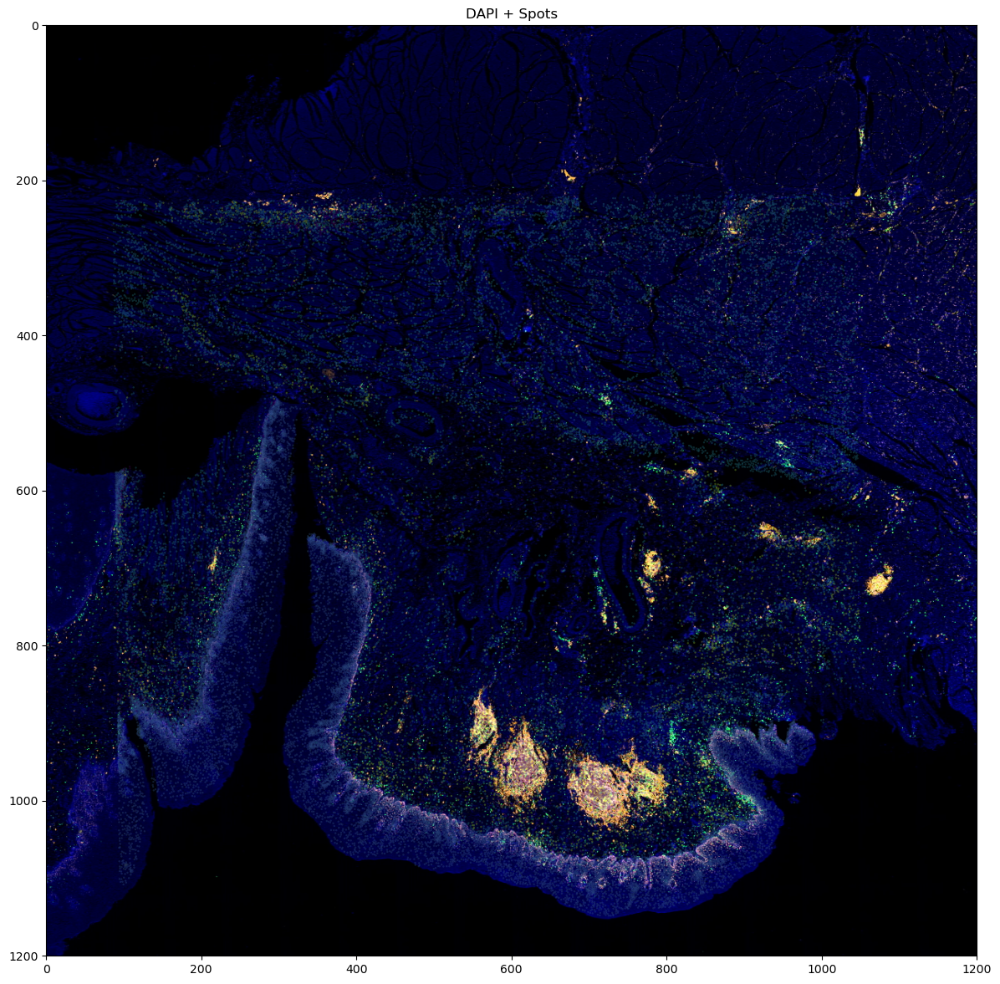

In [4]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R
import pandas as pd

# Load DAPI fluorescence image as background
dapi_bg = Image.open('./fluorescence/' + batch + '/3.jpg').convert('RGBA')
bg_w, bg_h = dapi_bg.size

# Parameter settings
opacity = 0.3
s = 3

# Get subset
subset = adata_HD[adata_HD.obs["batch"] == batch]
spots = subset.obsm['spatial']
spot_types = subset.obs['type']

trans_spots = spots @ [[x1[0], x1[3]], [x1[1], x1[4]]]
trans_spots = trans_spots + np.array([x1[2], x1[5]])

plt.figure(figsize=(bg_w / 100, bg_h / 100), dpi=100)

# Set coordinate system: (0, 0) at top-left, x to the right, y downward, range [0, bg_w] x [0, bg_h]
plt.imshow(dapi_bg, extent=[0, bg_w, bg_h, 0])

# Use transformed coordinates instead of the original spots
plt.scatter(
    trans_spots[:, 0],
    trans_spots[:, 1],
    c=pd.Categorical(spot_types).codes,
    s=s,
    alpha=opacity,
    edgecolors='none'
)

plt.title(f"DAPI + Spots")
plt.tight_layout()
plt.show()

In [5]:
'''
# nS02
corners = np.array([
    [12741.215800558577, 11195.78234303543],
    [14341.215800558577, 11195.78234303543],
    [14341.215800558577, 12795.78234303543],
    [12741.215800558577, 12795.78234303543]
])
'''
'''
# nS06
corners = np.array([[11820.44404614992,7449.243389502347],
[13420.44404614992,7449.243389502347],
[13420.44404614992,9049.243389502346],
[11820.44404614992,9049.243389502346]])
'''
'''
# nS01
corners = np.array([[3089.769422924311,5371.334366139769],
[4689.769422924312,5371.334366139769],
[4689.769422924312,6971.334366139769],
[3089.769422924311,6971.334366139769]])+[400,100]
'''
# nS03
corners = np.array([[10149.630231985078,12429.260604522182],
[11749.630231985078,12429.260604522182],
[11749.630231985078,14029.260604522182],
[10149.630231985078,14029.260604522182]])

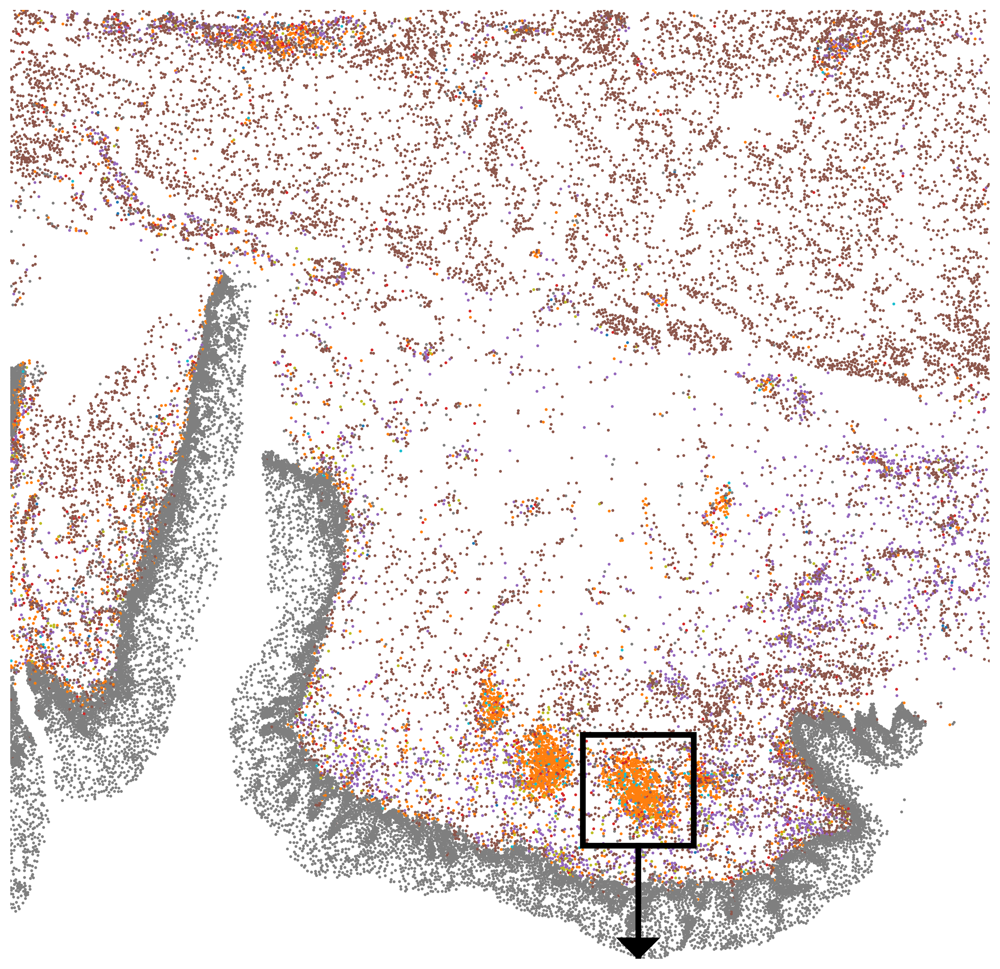

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import matplotlib.patches as patches
from matplotlib.patches import Polygon


# --- Helper functions ---
def get_rect(pts):
    pts = pts.astype(np.float32)
    box = cv2.boxPoints(cv2.minAreaRect(pts))
    y_s = box[np.argsort(box[:, 1])]
    t, b = y_s[:2][np.argsort(y_s[:2, 0])], y_s[2:][np.argsort(y_s[2:, 0])]
    return np.array([t[0], t[1], b[1], b[0]], dtype=np.float32)

def crop_rot(path, rect):
    img = cv2.imread(path)
    if img is None: raise FileNotFoundError(f"Image not found: {path}")
    w = int(max(np.linalg.norm(rect[0]-rect[1]), np.linalg.norm(rect[3]-rect[2])))
    h = int(max(np.linalg.norm(rect[0]-r[3]), np.linalg.norm(rect[1]-r[2]))) 
    dst = np.array([[0,0], [w,0], [w,h], [0,h]], dtype=np.float32)
    M = cv2.getPerspectiveTransform(rect, dst)
    return cv2.cvtColor(cv2.warpPerspective(img, M, (w, h)), cv2.COLOR_BGR2RGB)

# --- Core logic ---

# 1. Compute coordinate transformation
r = get_rect(spots)
org, ux, uy = r[3], (r[2]-r[3]), (r[0]-r[3])
M_mat = np.vstack([ux/np.linalg.norm(ux), uy/np.linalg.norm(uy)])
pts = (spots - org) @ M_mat.T
corners_new = (corners - org) @ M_mat.T

# 2. Compute target dimensions
w = int(max(np.linalg.norm(r[0]-r[1]), np.linalg.norm(r[3]-r[2])))
h = int(max(np.linalg.norm(r[0]-r[3]), np.linalg.norm(r[1]-r[2])))

# 3. Dynamically set canvas size
dpi = 1500
fig_w, fig_h = w / dpi, h / dpi
plt.figure(figsize=(fig_w, fig_h), dpi=300)

# === 4. Draw black frame and solid arrow (styles corrected) ===
# 1. Compute bounding box of the black frame
x_min, y_min = np.min(corners_new[:, 0]), np.min(corners_new[:, 1])
x_max, y_max = np.max(corners_new[:, 0]), np.max(corners_new[:, 1])

# --- 4.1 Draw black frame ---
box_line_width = 4
rect = patches.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min, 
                         fill=False, edgecolor='black', linewidth=box_line_width, zorder=100)
plt.gca().add_patch(rect)

# --- 4.2 Draw downward solid arrow (matching the OpenCV version) ---
# Compute midpoint of the top edge of the black frame (starting point / central axis of the arrow)
center_x = (x_min + x_max) / 2
center_y = y_min
tip_y = 5

# Define arrow parameters (to approximate the visual style of the OpenCV version)
line_thickness = 4  # shaft width
arrow_head_width = 300  # width of the arrow base

# 1. Draw shaft (thick line)
plt.plot([center_x, center_x], [center_y, tip_y], 
         color='black', linewidth=line_thickness, zorder=100)

# 2. Draw solid triangular arrowhead
# Apex: tip at the bottom (center_x, tip_y)
# Base vertices at the top
p1 = (center_x, 0)                # tip
p2 = (center_x - arrow_head_width, arrow_head_width)  # left base
p3 = (center_x + arrow_head_width, arrow_head_width)  # right base

# Create filled polygon
triangle = patches.Polygon([p1, p2, p3], 
                           closed=True, 
                           facecolor='black', 
                           edgecolor='black', 
                           zorder=100)
plt.gca().add_patch(triangle)

# === 5. Plot scatter points ===
color_mapping_dict = {
    'B cell': '#ff7f0e', 'Endothelial cell': '#1f77b4',
    'Epithelial cell': '#7f7f7f', 'Stromal cell': '#9467bd',
    'Muscle cell': '#8c564b', 'Myeloid cell': '#d62728',
    'Plasma cell': '#bcbd22', 'T cell': '#17becf'
}
point_colors = [color_mapping_dict[cell_type] for cell_type in subset.obs['type']]

plt.scatter(pts[:, 0], pts[:, 1], 
            c=point_colors, 
            s=4, 
            alpha=1.0, 
            edgecolors='none')

# === 6. Other settings ===
plt.axis('off')
# Ensure axis limits cover the black frame
plt.xlim(0, w)
plt.ylim(0, h)
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

plt.show()

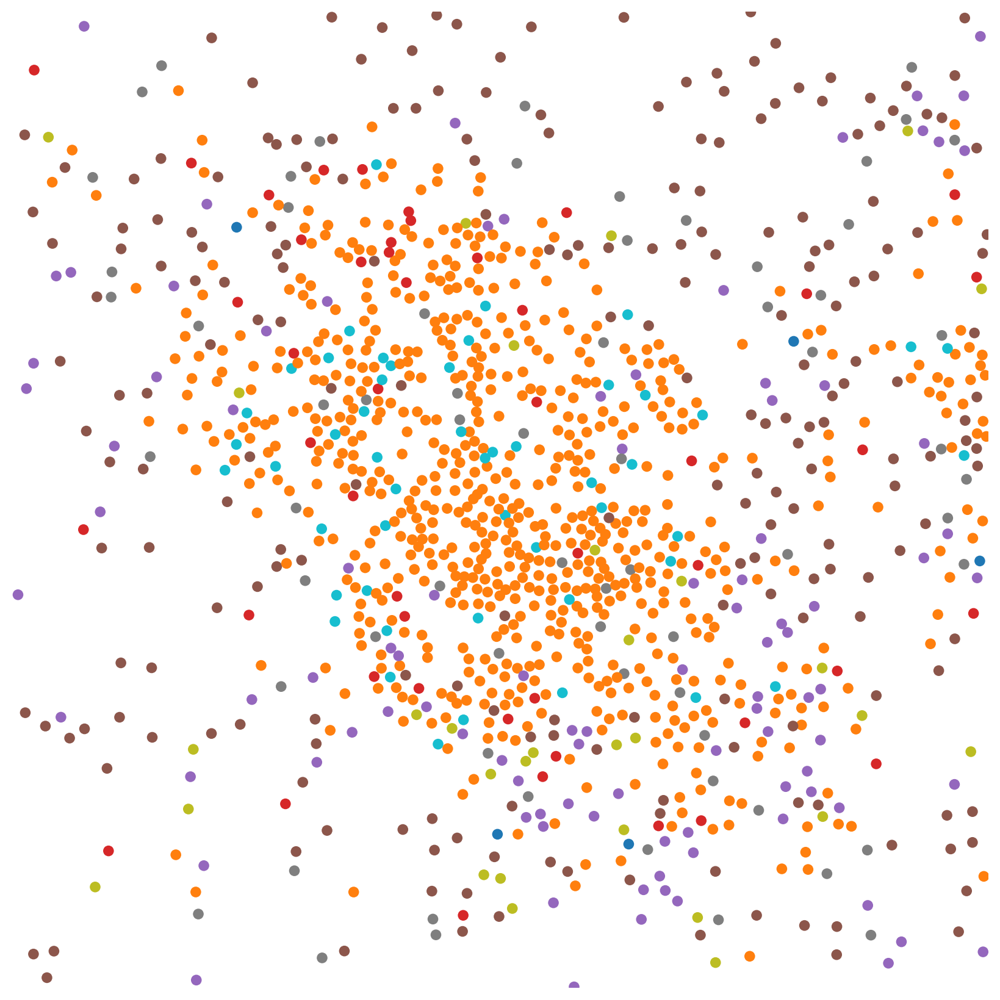

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Compute bounding box
x_min, x_max = corners[:, 0].min(), corners[:, 0].max()
y_min, y_max = corners[:, 1].min(), corners[:, 1].max()

# 2. Crop original data
mask = (spots[:, 0] >= x_min) & (spots[:, 0] <= x_max) & (spots[:, 1] >= y_min) & (spots[:, 1] <= y_max)

# 3. Prepare colors
cropped_pts = spots[mask]
cropped_types = spot_types[mask]
point_colors = [color_mapping_dict[cell_type] for cell_type in cropped_types]

# Compute region width and height (after translation, width is x_max - x_min)
w = x_max - x_min
h = y_max - y_min

# Dynamically compute canvas size
dpi = 200
fig_w, fig_h = w / dpi, h / dpi
plt.figure(figsize=(fig_w, fig_h), dpi=dpi)

plt.scatter(cropped_pts[:, 0], cropped_pts[:, 1], 
            c=point_colors, 
            s=40, 
            alpha=1.0, 
            edgecolors='none')

plt.axis('off')
plt.xlim(x_min, x_max)
plt.ylim(y_max, y_min)
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

plt.show()

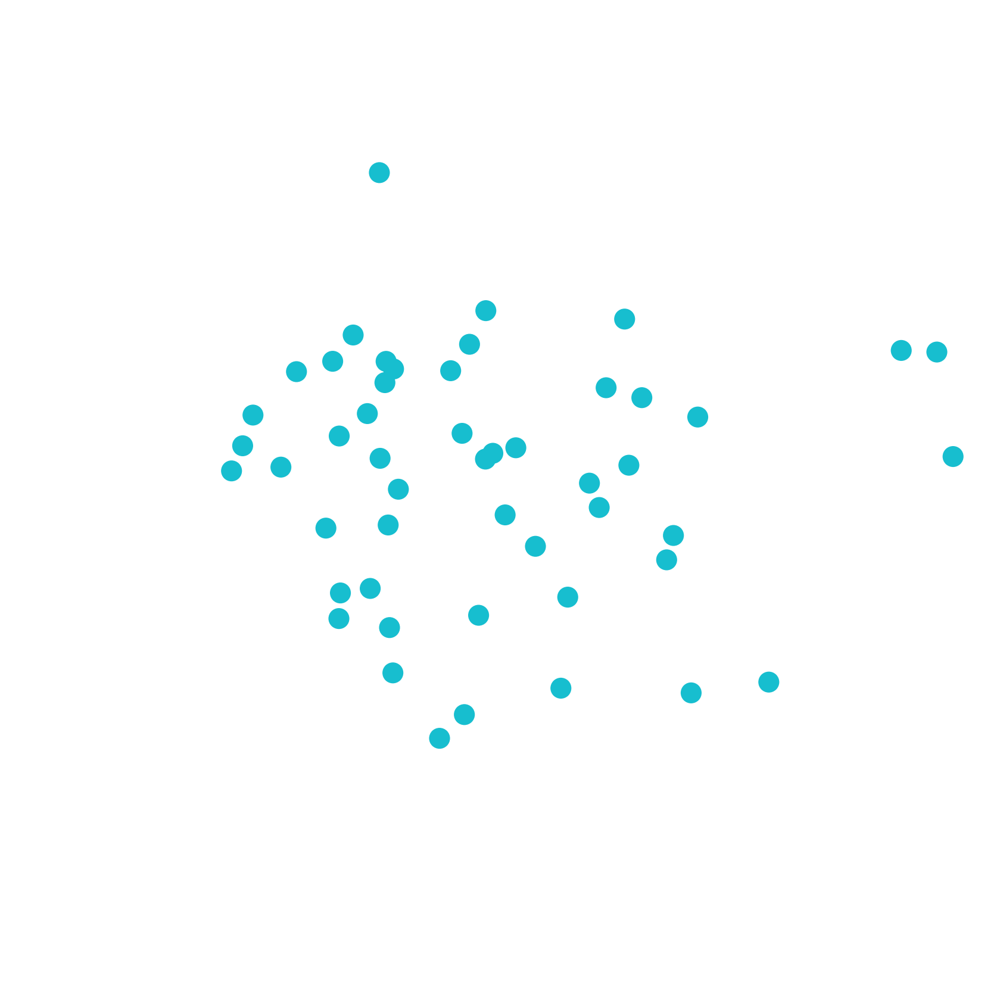

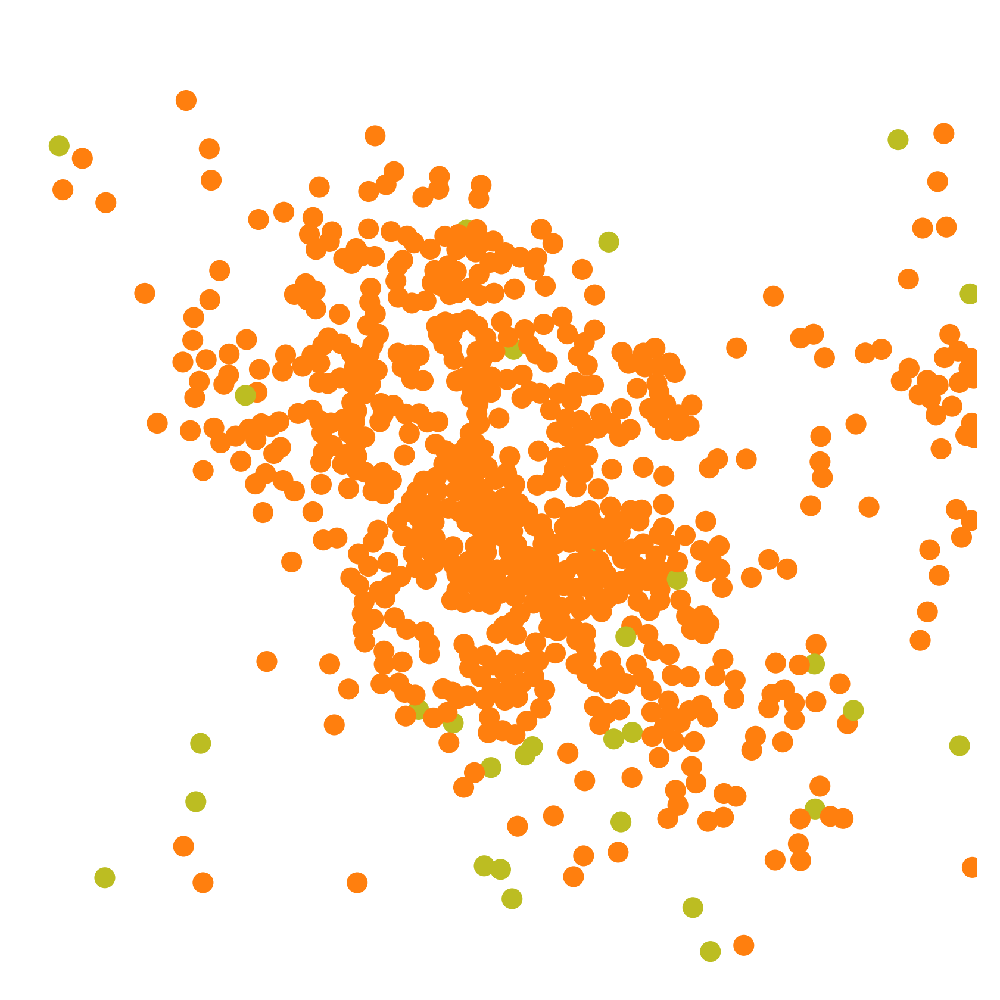

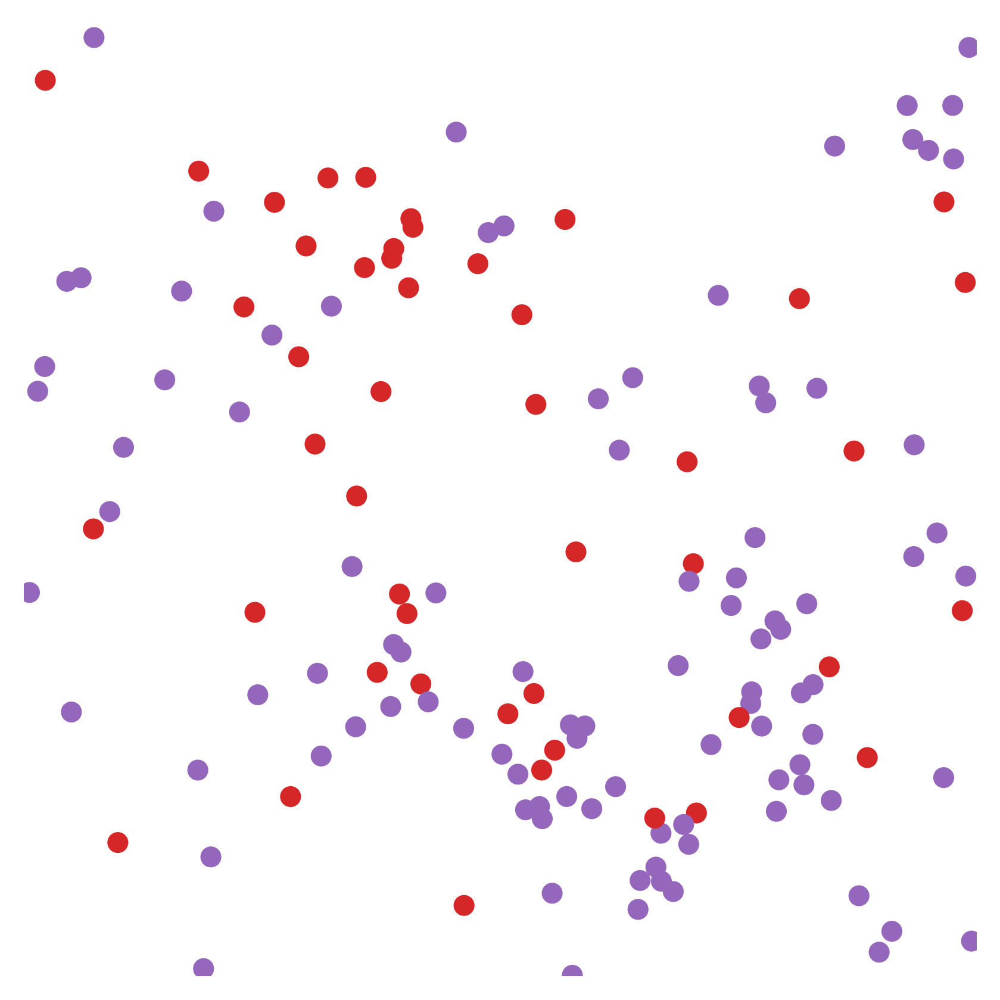

In [9]:
dpi = 400
fig_w, fig_h = w / dpi, h / dpi
for l in [["T cell"],["B cell","Plasma cell"],["Myeloid cell","Stromal cell"]]:
    plt.figure(figsize=(fig_w, fig_h), dpi=dpi)
    mask = cropped_types.isin(l)
    plt.scatter(cropped_pts[mask][:, 0], cropped_pts[mask][:, 1], 
                c=np.array(point_colors)[mask], 
                s=40, 
                alpha=1.0, 
                edgecolors='none')
    plt.axis('off')
    plt.xlim(x_min, x_max)
    plt.ylim(y_max, y_min)
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    n = ""
    for word in l:
        n+= word[0]
    plt.show()

In [15]:
'''
# nS02
src_points = [[ 944.18713145,  818.84595722],
        [1009.67674374,  821.16417358],
        [ 918.68675145,  788.12959039],
        [ 931.43694145,  750.45857447],
        [ 977.80126874,  751.03812856],
        [1010.25629783,  747.56080402],
        [ 982.43770146,  781.1749413 ],
        [1000.98343238,  766.68608902]]
dst_points = [[ 551.38723663, 1074.30676423],
        [1111.67287244, 1111.97302546],
        [ 327.74381057,  817.7053596 ],
        [ 436.03431161,  488.12557382],
        [ 831.53005454,  502.25042178],
        [1118.73529643,  476.35486719],
        [ 876.25873975,  761.20596775],
        [1031.63206733,  645.85304273]]
'''
'''
# nS06
src_points = [[855.22926833, 602.72297419],
        [826.58550961, 605.1516369 ],
        [912.22133909, 622.18417757],
        [911.27508683, 555.9465194 ],
        [884.78002357, 666.18490764],
        [960.0070782 , 607.99039368],
        [957.64144755, 646.78673632]]
dst_points = [[ 321.51923441,  487.20588013],
        [ 110.24362955,  550.81573965],
        [ 753.15756692,  568.98998523],
        [ 646.38387414,   91.91603877],
        [ 591.8611374 ,  907.48530915],
        [1071.20686456,  403.14999432],
        [1103.01179433,  682.57902011]]
'''
'''
# nS01
src_points = [[279.17518101744525, 516.2942874813344],
[289.3086829093571, 510.03634584095687],
[201.24059787056268, 454.9135297387981],
[259.706756054044, 401.8009790426434],
[347.05408295924894, 445.30394394320547],
[293.70467393186874, 422.2844670784975],
[273.301674676114, 458.0548607864299]]
dst_points = [
    [729.0454545454546, 928.7207792207791], 
    [787.4870129870131, 899.4999999999998], 
    [253.72077922077938, 552.7467532467531], 
    [594.6298701298703, 225.47402597402584], 
    [1145.9285714285716, 494.30519480519456], 
    [816.7077922077923, 350.1493506493505], 
    [692.0324675324676, 585.8636363636361]
]
'''
# nS03
src_points = [[ 697.06460311,  938.91427944],
       [ 730.84687358, 1051.41853797],
       [ 677.84899972,  998.73059321],
       [ 680.01850333,  959.05967008],
       [ 775.47666209,  948.83201022],
       [ 752.54190966,  985.09371338],
       [ 756.2610587 , 1031.27314733],
       [ 656.15396364,  945.11286118]]
dst_points = [[ 503.94500889,  132.33210566],
       [ 787.40957582, 1077.21399543],
       [ 345.4486919 ,  635.25311151],
       [ 360.68872238,  309.11645923],
       [1153.17030734,  220.72428245],
       [ 967.24193548,  522.47688595],
       [ 997.72199644,  903.47764796],
       [ 156.47231394,  184.1482093 ]]
s,R,t =estimate_similarity_transform(src_points, dst_points)
x2 = [s*R[0,0],s*R[0,1],t[0],s*R[1,0],s*R[1,1],t[1]]

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ================= Modified crop_rot function =================
def crop_rot_with_box(path, rect, highlight_rect=None):
    """
    path: image file path
    rect: rotated rectangle defining the crop region (from get_rect)
    highlight_rect: slanted box coordinates in the original image coordinate system (corners_new)
    """
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Image not found: {path}")

    # 1. Compute crop dimensions
    w = int(max(np.linalg.norm(rect[0] - rect[1]), np.linalg.norm(rect[3] - rect[2])))
    h = int(max(np.linalg.norm(rect[0] - rect[3]), np.linalg.norm(rect[1] - rect[2])))

    # 2. Compute perspective transform matrix M
    dst = np.array([[0, 0], [w, 0], [w, h], [0, h]], dtype=np.float32)
    M = cv2.getPerspectiveTransform(rect.astype(np.float32), dst)

    # 3. Crop / rotate the image (without drawing the box yet)
    cropped_img = cv2.warpPerspective(img, M, (w, h))

    # 4. If highlight_rect is provided, draw the box and solid arrow on the cropped image
    if highlight_rect is not None:
        # --- Key step: compute the precise position of the box in the cropped image ---
        pts = highlight_rect.astype(np.float32).reshape(-1, 1, 2)
        transformed_pts = cv2.perspectiveTransform(pts, M)
        transformed_pts = transformed_pts.astype(np.int32)  # convert to int for drawing

        # --- Draw white box on the cropped image ---
        box_thickness = 4
        cv2.polylines(cropped_img, [transformed_pts], isClosed=True,
                      color=(255, 255, 255), thickness=box_thickness)

        # --- New: draw a downward solid arrow ---

        # 1. Get the two bottom-edge points of the white box: bottom-left (index 3) and bottom-right (index 2)
        pt_bottom_left = transformed_pts[3][0]
        pt_bottom_right = transformed_pts[2][0]

        # 2. Compute the midpoint of the bottom edge (starting point / central axis of the arrow)
        center_x = int((pt_bottom_left[0] + pt_bottom_right[0]) / 2)
        center_y = int((pt_bottom_left[1] + pt_bottom_right[1]) / 2)

        # 3. Define arrow parameters
        arrow_width = 20      # width of the arrow base in pixels
        line_thickness = 4    # shaft width

        # 4. Draw the shaft (a thick line)
        tip_y = h
        cv2.line(cropped_img, (center_x, center_y), (center_x, tip_y),
                 (255, 255, 255), thickness=line_thickness)

        # 5. Draw a solid triangular arrowhead
        # Three vertices of the triangle: bottom-left, bottom-right, and top-center (tip)
        # The arrow points downward, so the tip is at the bottom
        # Here we draw an inverted triangle with the tip at (center_x, tip_y)

        # Vertex 1: arrow tip
        p1 = (center_x, tip_y)
        # Vertex 2: left base corner of the arrow
        p2 = (center_x - arrow_width, tip_y - arrow_width)
        # Vertex 3: right base corner of the arrow
        p3 = (center_x + arrow_width, tip_y - arrow_width)

        # Combine the three points into an array
        triangle_pts = np.array([p1, p2, p3], dtype=np.int32)

        # Fill the triangle (solid)
        cv2.fillPoly(cropped_img, [triangle_pts], (255, 255, 255))

    # 5. Convert back to RGB
    return cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB)

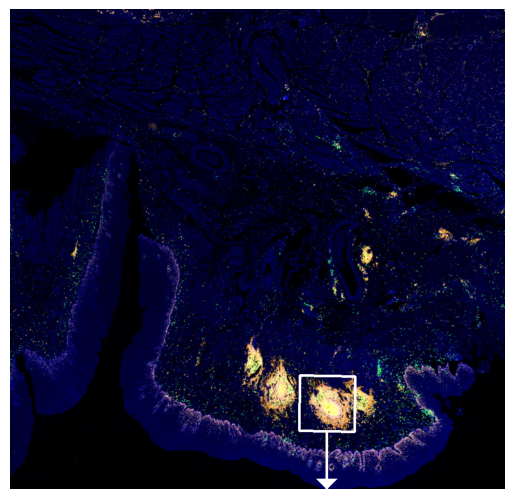

In [17]:
r = get_rect(trans_spots) 

corners_new = corners@ [[x1[0],x1[3]],[x1[1],x1[4]]] + np.array([x1[2],x1[5]])
img_tot = crop_rot_with_box('./fluorescence/'+batch.split("-")[0]+'/3.jpg', r,corners_new)

plt.imshow(img_tot)
plt.axis('off')  
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
plt.show()

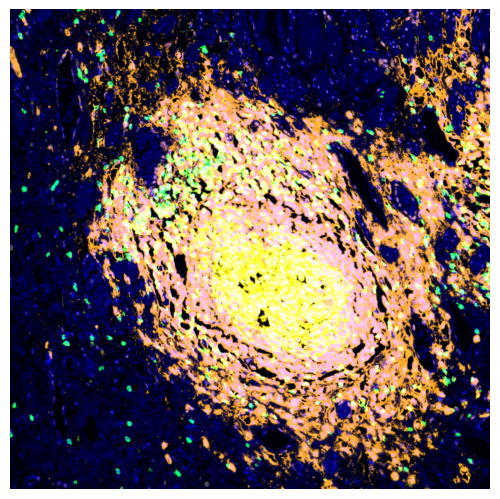

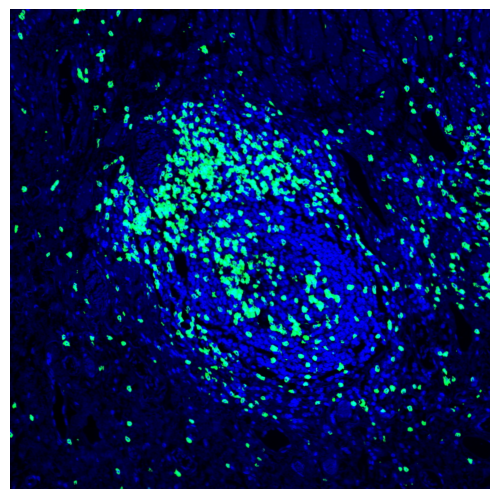

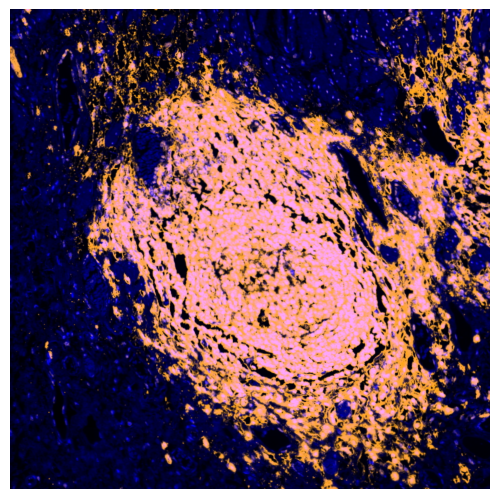

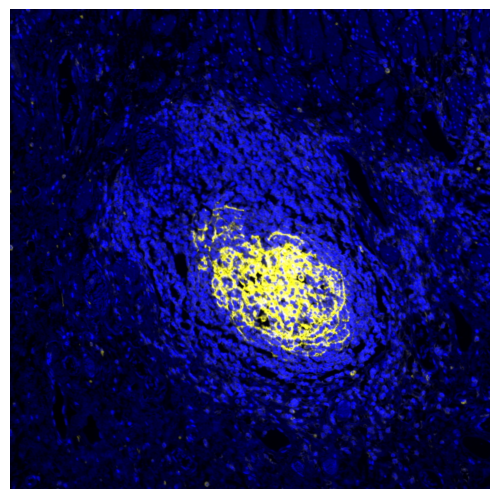

In [18]:
tp = corners@[[x1[0],x1[3]],[x1[1],x1[4]]]+ np.array([x1[2], x1[5]])
tp = tp@[[x2[0],x2[3]],[x2[1],x2[4]]]+ np.array([x2[2], x2[5]])
r = get_rect(tp)

for n in ["3s","CD3s","CD20s","CD23s"]:
    img_tot = crop_rot('./fluorescence/'+batch+'/'+n+'.jpg', r)
    
    plt.imshow(img_tot)
    plt.axis('off')  
    plt.subplots_adjust(left=0, right=1, top=1, bottom=0)
    plt.show()